# Project 1:Gallstone dataset 

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, RepeatedStratifiedKFold
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.pipeline import  make_pipeline
from sklearn.preprocessing import  StandardScaler 
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.metrics import confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.model_selection import GridSearchCV, StratifiedKFold, validation_curve

### References
Esen, I., Arslan, H., Aktürk, S., Gülşen, M., Kültekin, N., & Özdemir, O. (2024). *Gallstone* [Data set]. UCI Machine Learning Repository. https://archive.ics.uci.edu/dataset/1150/gallstone-1


## Initial Data Review




**Class labels of the dataset:** 
- **Gallstone Status**: 
    - **0 = gallstones present (Yes)**
    - **1 = no gallstones (No)**
- **Gender**
    - **: 0 = male**
    - **: 1 = Female**

In [2]:
galle_set = pd.read_csv('dataset-uci.csv') #(Esen et al., 2024)
galle_set

,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
314,1,49,0,0,0,0,0,0,178,88.8,...,55.0,81.0,28.0,50.0,90.0,0.98,94.50,6.2,16.5,8.3
315,1,31,1,0,0,0,0,0,157,53.4,...,58.0,64.0,24.0,16.0,38.0,0.50,128.50,0.0,12.5,24.0
316,1,58,0,0,0,0,0,0,172,96.6,...,45.0,168.0,21.0,27.0,94.0,1.04,83.23,0.0,15.4,15.7
317,1,37,1,0,0,0,0,0,177,88.4,...,33.0,253.0,40.0,22.0,115.0,1.01,98.23,0.4,16.0,33.3


In [3]:
galle_set.columns

Index(['Gallstone Status', 'Age', 'Gender', 'Comorbidity',
       'Coronary Artery Disease (CAD)', 'Hypothyroidism', 'Hyperlipidemia',
       'Diabetes Mellitus (DM)', 'Height', 'Weight', 'Body Mass Index (BMI)',
       'Total Body Water (TBW)', 'Extracellular Water (ECW)',
       'Intracellular Water (ICW)',
       'Extracellular Fluid/Total Body Water (ECF/TBW)',
       'Total Body Fat Ratio (TBFR) (%)', 'Lean Mass (LM) (%)',
       'Body Protein Content (Protein) (%)', 'Visceral Fat Rating (VFR)',
       'Bone Mass (BM)', 'Muscle Mass (MM)', 'Obesity (%)',
       'Total Fat Content (TFC)', 'Visceral Fat Area (VFA)',
       'Visceral Muscle Area (VMA) (Kg)', 'Hepatic Fat Accumulation (HFA)',
       'Glucose', 'Total Cholesterol (TC)', 'Low Density Lipoprotein (LDL)',
       'High Density Lipoprotein (HDL)', 'Triglyceride',
       'Aspartat Aminotransferaz (AST)', 'Alanin Aminotransferaz (ALT)',
       'Alkaline Phosphatase (ALP)', 'Creatinine',
       'Glomerular Filtration Rate (GFR

**Data Overview**

In [4]:
counts = galle_set['Gallstone Status'].value_counts().sort_index()
share = (galle_set['Gallstone Status'].value_counts(normalize=True).sort_index() * 100).round(1)
pd.DataFrame({'Patients': counts, 'Percent': share}, index=pd.Index([0, 1], name='Gallstone Status')).rename(
    index={0: '0 (gallstones present)', 1: '1 (no gallstones)'})

,Patients,Percent
Gallstone Status,,
0 (gallstones present),161,50.5
1 (no gallstones),158,49.5


Out of 319 patients in total, 161 do have gallestone and 158 do not have gallestone. This means that gallestone column is bianry with two classes; 0 and 1.  Where 0 means gallestone and 1 means no gallestone. Therefore the dataset is balanced with 50.5 % of patents belongs to class 0 and 49.5% of the patient belongs to class 1. 

**Feature overview**

In [5]:
# Create a summary table for all columns
summary = pd.DataFrame({
    "Data Type": galle_set.dtypes.astype(str),
    "Unique Values": galle_set.nunique(),
    "Missing Values": galle_set.isnull().sum(),
    "Mean": galle_set.mean(numeric_only=True).round(2),
    "Median": galle_set.median(numeric_only=True).round(2),
    "Std": galle_set.std(numeric_only=True).round(2),
    "Minimum": galle_set.min(),
    "Maximum": galle_set.max()
})

display(summary)



,Data Type,Unique Values,Missing Values,Mean,Median,Std,Minimum,Maximum
Gallstone Status,int64,2,0,0.50,0.00,0.50,0.00,1.00
Age,int64,56,0,48.07,49.00,12.11,20.00,96.00
Gender,int64,2,0,0.49,0.00,0.50,0.00,1.00
Comorbidity,int64,4,0,0.34,0.00,0.52,0.00,3.00
Coronary Artery Disease (CAD),int64,2,0,0.04,0.00,0.19,0.00,1.00
Hypothyroidism,int64,2,0,0.03,0.00,0.17,0.00,1.00
Hyperlipidemia,int64,2,0,0.03,0.00,0.16,0.00,1.00
Diabetes Mellitus (DM),int64,2,0,0.13,0.00,0.34,0.00,1.00
Height,int64,46,0,167.16,168.00,10.05,145.00,191.00
Weight,float64,245,0,80.56,78.80,15.71,42.90,143.50


This shows that the dataset has 319 patients and 39 columns. All the columns are numeric; 28 float64 and 11 int64. 

## Data Cleaning

### 2.1 Duplicates and missing values

In [6]:
print("\nGallstone Status distribution:")
galle_set['Gallstone Status'].value_counts()




Gallstone Status distribution:


Gallstone Status
0    161
1    158
Name: count, dtype: int64

In [7]:
# Check for duplicate rows
print('Shape of dataset before removing duplicates', galle_set.shape)
print('Number of duplicates', galle_set.duplicated().sum())

# Check for missing values in each column
print("\nMissing values per column:")
print(galle_set.isnull().sum())

# Check total number of missing values
print("\nTotal missing values:", galle_set.isnull().sum().sum())

Shape of dataset before removing duplicates (319, 39)
Number of duplicates 0

Missing values per column:
Gallstone Status                                  0
Age                                               0
Gender                                            0
Comorbidity                                       0
Coronary Artery Disease (CAD)                     0
Hypothyroidism                                    0
Hyperlipidemia                                    0
Diabetes Mellitus (DM)                            0
Height                                            0
Weight                                            0
Body Mass Index (BMI)                             0
Total Body Water (TBW)                            0
Extracellular Water (ECW)                         0
Intracellular Water (ICW)                         0
Extracellular Fluid/Total Body Water (ECF/TBW)    0
Total Body Fat Ratio (TBFR) (%)                   0
Lean Mass (LM) (%)                                0
Body Protei

In [8]:
missing_markers = ["?", "NA", "N/A", "unknown", "", "null"]

print("Checking for hidden missing values:\n")

total_hidden = 0

for col in galle_set.columns:
    values = galle_set[col].astype("string").str.strip().str.lower()

    count = values.isin(
        [x.lower() for x in missing_markers]
    ).sum()

    print(f"{col}: {count}")
    total_hidden += count

print(f"\nTotal hidden missing values: {total_hidden}")

Checking for hidden missing values:

Gallstone Status: 0
Age: 0
Gender: 0
Comorbidity: 0
Coronary Artery Disease (CAD): 0
Hypothyroidism: 0
Hyperlipidemia: 0
Diabetes Mellitus (DM): 0
Height: 0
Weight: 0
Body Mass Index (BMI): 0
Total Body Water (TBW): 0
Extracellular Water (ECW): 0
Intracellular Water (ICW): 0
Extracellular Fluid/Total Body Water (ECF/TBW): 0
Total Body Fat Ratio (TBFR) (%): 0
Lean Mass (LM) (%): 0
Body Protein Content (Protein) (%): 0
Visceral Fat Rating (VFR): 0
Bone Mass (BM): 0
Muscle Mass (MM): 0
Obesity (%): 0
Total Fat Content (TFC): 0
Visceral Fat Area (VFA): 0
Visceral Muscle Area (VMA) (Kg): 0
Hepatic Fat Accumulation (HFA): 0
Glucose: 0
Total Cholesterol (TC): 0
Low Density Lipoprotein (LDL): 0
High Density Lipoprotein (HDL): 0
Triglyceride: 0
Aspartat Aminotransferaz (AST): 0
Alanin Aminotransferaz (ALT): 0
Alkaline Phosphatase (ALP): 0
Creatinine: 0
Glomerular Filtration Rate (GFR): 0
C-Reactive Protein (CRP): 0
Hemoglobin (HGB): 0
Vitamin D: 0

Total hid


**The dataset was checked for missing values, duplicate rows, and hidden missing markes. No issues were identified during those steps. Therefore no missing value imputation or duplicate removal was required, as the dataset was already complete and free of duplicate records.**


### 2.2 Inconsistencies

**In addition we need to check if the dataset contains unrealistc or invalid values. This is done to identify potential data entry errors, values outside reasonable ranges, and extreme observations that may affect further analysis.**

In [9]:
#sorted from fewest to most
print("\n Number of unique values per column:")
galle_set.nunique().sort_values()


 Number of unique values per column:


Gallstone Status                                    2
Gender                                              2
Hypothyroidism                                      2
Coronary Artery Disease (CAD)                       2
Hyperlipidemia                                      2
Diabetes Mellitus (DM)                              2
Comorbidity                                         4
Hepatic Fat Accumulation (HFA)                      5
Visceral Fat Rating (VFR)                          22
Bone Mass (BM)                                     25
Aspartat Aminotransferaz (AST)                     44
Height                                             46
Age                                                56
High Density Lipoprotein (HDL)                     63
Alanin Aminotransferaz (ALT)                       67
Creatinine                                         76
Glucose                                            78
Extracellular Fluid/Total Body Water (ECF/TBW)     81
Hemoglobin (HGB)            

In [10]:
# Check ranges for selected numerical features
columns_to_check = [
    "Age",
    "Height",
    "Weight",
    "Body Mass Index (BMI)",
    "Glucose",
    "Vitamin D"
   
]

display(galle_set[columns_to_check].describe().T)

,count,mean,std,min,25%,50%,75%,max
Age,319.0,48.068966,12.114558,20.0,38.50,49.0,56.00,96.0
Height,319.0,167.156740,10.053030,145.0,159.50,168.0,175.00,191.0
Weight,319.0,80.564890,15.709069,42.9,69.60,78.8,91.25,143.5
Body Mass Index (BMI),319.0,28.877116,5.313707,17.4,25.25,28.3,31.85,49.7
Glucose,319.0,108.688715,44.848714,69.0,92.00,98.0,109.00,575.0
Vitamin D,319.0,21.401411,9.981659,3.5,13.25,22.0,28.06,53.1


 The most notable finding from this table is the maximum glucose value of 575, which is  higher than the median value of 98. 

In [11]:
# Check patients with unusually high glucose value
display(
    galle_set[galle_set["Glucose"] > 300][
        ["Age", "Glucose", "Diabetes Mellitus (DM)", "Gallstone Status"]
    ]
)

,Age,Glucose,Diabetes Mellitus (DM),Gallstone Status
20,50,374.0,1,0
40,33,575.0,0,0
310,50,325.0,1,1
312,51,375.0,1,1


This shows that four have glucose values over 300. Three of those have DM with value 1, except the one with the highes value. Where he has DM= 0. This may indicate a potential inconsistency in the dataset.

In [12]:
#Ranges of numerical variables
numerical_columns=galle_set.select_dtypes(include='number').columns
ranges=pd.DataFrame({
    'Minimum': galle_set[numerical_columns].min(),
    'Maximum': galle_set[numerical_columns].max(),
})
ranges

,Minimum,Maximum
Gallstone Status,0.00,1.00
Age,20.00,96.00
Gender,0.00,1.00
Comorbidity,0.00,3.00
Coronary Artery Disease (CAD),0.00,1.00
Hypothyroidism,0.00,1.00
Hyperlipidemia,0.00,1.00
Diabetes Mellitus (DM),0.00,1.00
Height,145.00,191.00
Weight,42.90,143.50


The minimum and maximum values show that most variables lie in reasonable ranges. The clear exception is **Obesity (%)** with a maximum of 1954, which is focused below.

<span style="color:hotpink;"> Obesity has a very large value compared to the rest. 

In [13]:
#Controlling high value in obesity  
galle_set[galle_set['Obesity (%)']>100][
    ['Gallstone Status', 'Age', 'Height', 'Weight', 'Body Mass Index (BMI)', 'Obesity (%)']
]

,Gallstone Status,Age,Height,Weight,Body Mass Index (BMI),Obesity (%)
23,0,57,170,143.5,49.7,125.6
209,1,64,150,102.1,45.4,106.3
239,1,51,150,65.9,29.3,1954.0


<span style="color:hotpink;"> Only three observations have an obesity value above 100. Taken BMI into comparison and consideration toward obesity, the lowest values seems legit. The value of 1954 is suspicious. 

#### 2.2.1 Consistency checks between variables

- **BMI:** BMI = weight (kg) / [height (m)]^2 or BMI = [weight (kg) / height (cm) / height (cm)] x 10,000 ([CDC](https://www.cdc.gov/growth-chart-training/hcp/using-bmi/calculating-bmi.html))

- **Total cholesterol:** TC ≈ LDL + HDL + TG/5 (Not valid when TG ≥ 400 mg/dL ) ([MSD Manuals](https://www.msdmanuals.com/iframe/manual/medical-calculators/friedewald.htm))

- **GFR:** GFR ≥ 90 (Normal value of GFR) ([KDIGO table](https://pmc.ncbi.nlm.nih.gov/articles/PMC8941542/table/tab2))

-  **Fasting glucose:** ≤ 99 mg/dL normal, 100–125 mg/dL prediabetes, ≥ 126 mg/dL diabetes ([CDC](https://www.cdc.gov/diabetes/diabetes-testing/index.html))


In [14]:
ref = {}

bmi_calc = galle_set['Weight'] / (galle_set['Height'] / 100) ** 2
ref['BMI differs from weight/height² (> 1.5)'] = (bmi_calc - galle_set['Body Mass Index (BMI)']).abs() > 1.5


ldl_calc = (galle_set['Total Cholesterol (TC)']
            - galle_set['High Density Lipoprotein (HDL)']
            - galle_set['Triglyceride'] / 5)
valid_tg = galle_set['Triglyceride'] < 400
ref['LDL differs from Friedewald (> 30, TG < 400)'] = valid_tg & ((ldl_calc - galle_set['Low Density Lipoprotein (LDL)']).abs() > 30)


ref['GFR < 30 with creatinine < 1.0'] = (galle_set['Glomerular Filtration Rate (GFR)'] < 30) & (galle_set['Creatinine'] < 1.0)


dm = galle_set['Diabetes Mellitus (DM)']
glucose = galle_set['Glucose']
ref['DM = 0 but glucose >= 126'] = (dm == 0) & (glucose >= 126)
ref['DM = 1 but glucose <= 99'] = (dm == 1) & (glucose <= 99)


consistency_summary = pd.DataFrame({
    'Rows': {name: int(mask.sum()) for name, mask in ref.items()},
    'Row index (first 15)': {name: list(galle_set.index[mask][:15]) for name, mask in ref.items()},
})
display(consistency_summary)

,Rows,Row index (first 15)
BMI differs from weight/height² (> 1.5),3,"[46, 116, 129]"
"LDL differs from Friedewald (> 30, TG < 400)",20,"[3, 4, 11, 71, 78, 95, 127, 171, 173, 194, 205..."
GFR < 30 with creatinine < 1.0,3,"[117, 272, 308]"
DM = 0 but glucose >= 126,12,"[26, 28, 40, 62, 79, 81, 83, 107, 121, 187, 30..."
DM = 1 but glucose <= 99,5,"[15, 39, 56, 165, 213]"



- **BMI** disagrees with the formula in 3 patients, so one of the three values is wrong in each.
- **LDL** disagrees with the Friedewald calculation in 20 patients (only patients with TG < 400 are checked).
- **GFR** is below 30 with a normal creatinine (< 1.0) in 3 patients
- **Diabetes label vs glucose:** 12 patients have DM = 0 with fasting-range glucose ≥ 126, and 5 patients have DM = 1 with glucose ≤ 99. 



In [15]:
if 'galle_raw' not in globals():    
    galle_raw = galle_set.copy()      # keep the original
galle_clean = galle_raw.copy()


bad_bmi = ref['BMI differs from weight/height² (> 1.5)']
galle_clean.loc[bad_bmi, 'Body Mass Index (BMI)'] = (
    galle_raw['Weight'] / (galle_raw['Height'] / 100) ** 2).round(1)[bad_bmi]

bad_gfr = ref["GFR < 30 with creatinine < 1.0"]
gfr_col = "Glomerular Filtration Rate (GFR)"


 
imputer = SimpleImputer(strategy="median") # Create an imputer that uses the median to fill incorrect values.
imputer.fit(galle_clean.loc[~bad_gfr, [gfr_col]]) # Fit the imputer using only valid GFR values.

galle_clean.loc[bad_gfr, gfr_col] = imputer.statistics_[0] 

display(galle_clean.loc[bad_gfr, [gfr_col]])

galle_flags = pd.DataFrame({
    'flag_dm_glucose': ref['DM = 0 but glucose >= 126'] | ref['DM = 1 but glucose <= 99'],
    'flag_friedewald': ref['LDL differs from Friedewald (> 30, TG < 400)'],
}).astype(int)

print('Rows before/after:', galle_raw.shape[0], '/', galle_clean.shape[0], '(no rows removed)')
changed = (galle_raw.ne(galle_clean) & ~(galle_raw.isna() & galle_clean.isna())).sum()
print('\nValues changed per column:')
print(changed[changed > 0].to_string())
print('\nNew missing values (NaN):')
print(galle_clean.isna().sum()[galle_clean.isna().sum() > 0].to_string())
print('\nFlagged rows:')
print(galle_flags.sum().to_string())

,Glomerular Filtration Rate (GFR)
117,104.05
272,104.05
308,104.05


Rows before/after: 319 / 319 (no rows removed)

Values changed per column:
Body Mass Index (BMI)               3
Glomerular Filtration Rate (GFR)    3

New missing values (NaN):
Series([], )

Flagged rows:
flag_dm_glucose    17
flag_friedewald    20


In [16]:

galle_set = galle_clean.copy()    

bmi_calc = galle_set['Weight'] / (galle_set['Height'] / 100) ** 2
after = {
    'BMI differs from weight/height² (> 1.5)': ((bmi_calc - galle_set['Body Mass Index (BMI)']).abs() > 1.5).sum(),
    'GFR < 30 with creatinine < 1.0': ((galle_set['Glomerular Filtration Rate (GFR)'] < 30) & (galle_set['Creatinine'] < 1.0)).sum(),
}
pd.DataFrame({'Before': {k: int(ref[k].sum()) for k in after}, 'After': after})

,Before,After
BMI differs from weight/height² (> 1.5),3,0
GFR < 30 with creatinine < 1.0,3,0


### Data Cleaning Summary

- **Missing values:** No missing values were found in the original dataset.
- **Duplicates:** No duplicate rows were found.
- **Hidden markers:** No hidden markers were found.
- **Unrealistic Values:** The dataset contains a few potentially unrealistic values, particularly in the glucose and obesity variables. Some observations exceed the expected ranges, suggesting possible outliers or data entry errors that require further investigation.

    - Glucose= 575 is extreme, but possible, so it is kept and flagged because the patient has DM = 0. 
    
- **Recalculates:** BMI in three rows were disagreed with the formula. Therefore it was recalculated in those rows. 
- **Rows removed:** zero rows were removed (319 before and after)
- **Flagged but kept:** 37 rows have values that do not match each other (diabetes label vs glucose, and LDL vs cholesterol calculation). They are kept as they are and only marked, because we do not know which value is wrong.
- **Set to `NaN`:** GFR in 3 rows are set to NaN. 






## Visualization


In this section, we visualize the dataset to explore patterns and relationships between the different features and gallstone status.


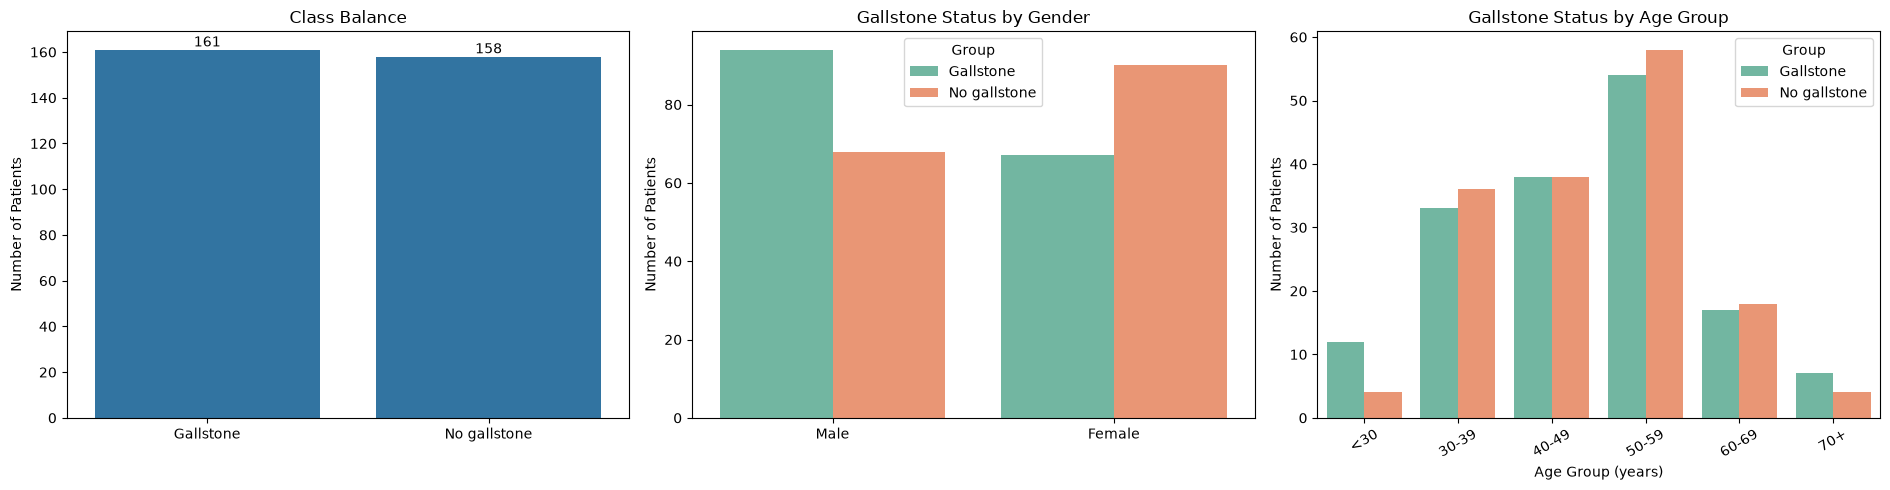

In [17]:
# Prepare data
labels = {0: 'Gallstone', 1: 'No gallstone'}
order = ['Gallstone', 'No gallstone']

status = galle_set['Gallstone Status'].map(labels)


age_group = pd.cut(
    galle_set['Age'],
    bins=[0, 30, 40, 50, 60, 70, float('inf')],
    labels=['<30', '30-39', '40-49', '50-59', '60-69', '70+'],
    right=False
)

# Prepare gender and age data
gender = galle_set.assign(
    Gender=galle_set['Gender'].map({0: 'Male', 1: 'Female'}),
    Group=status
)

age_data = galle_set.assign(
    Age_Group=age_group,
    Group=status
)

# Create 3 subplots
fig, axes = plt.subplots(1, 3, figsize=(19, 5))


sns.countplot(
    x=status,
    order=order,
    ax=axes[0]
)

axes[0].set_title('Class Balance')
axes[0].set_xlabel('')
axes[0].set_ylabel('Number of Patients')

for p in axes[0].patches:
    axes[0].annotate(
        int(p.get_height()),
        (p.get_x() + p.get_width()/2, p.get_height()),
        ha='center',
        va='bottom'
    )


sns.countplot(
    x='Gender',
    hue='Group',
    hue_order=order,
    data=gender,
    palette='Set2',
    ax=axes[1]
)

axes[1].set_title('Gallstone Status by Gender')
axes[1].set_xlabel('')
axes[1].set_ylabel('Number of Patients')


sns.countplot(
    x='Age_Group',
    hue='Group',
    hue_order=order,
    data=age_data,
    palette='Set2',
    ax=axes[2]
)

axes[2].set_title('Gallstone Status by Age Group')
axes[2].set_xlabel('Age Group (years)')
axes[2].set_ylabel('Number of Patients')
axes[2].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

share_gender = (
    (galle_set['Gallstone Status'] == 0)
    .groupby(galle_set['Gender'])
    .mean() * 100
).round(1)



share_age = (
    (galle_set['Gallstone Status'] == 0)
    .groupby(age_group, observed=True)
    .mean() * 100
).round(1)




This plot show that the dataset has an even split between gender (162 men, 157 women). Gallstones are more common among men than women. Affecting approximately 58% of male patients compared to 43% of female patients. The age group 50–59 has the highest number of gallstone cases, while the youngest and oldest age groups have fewer cases.

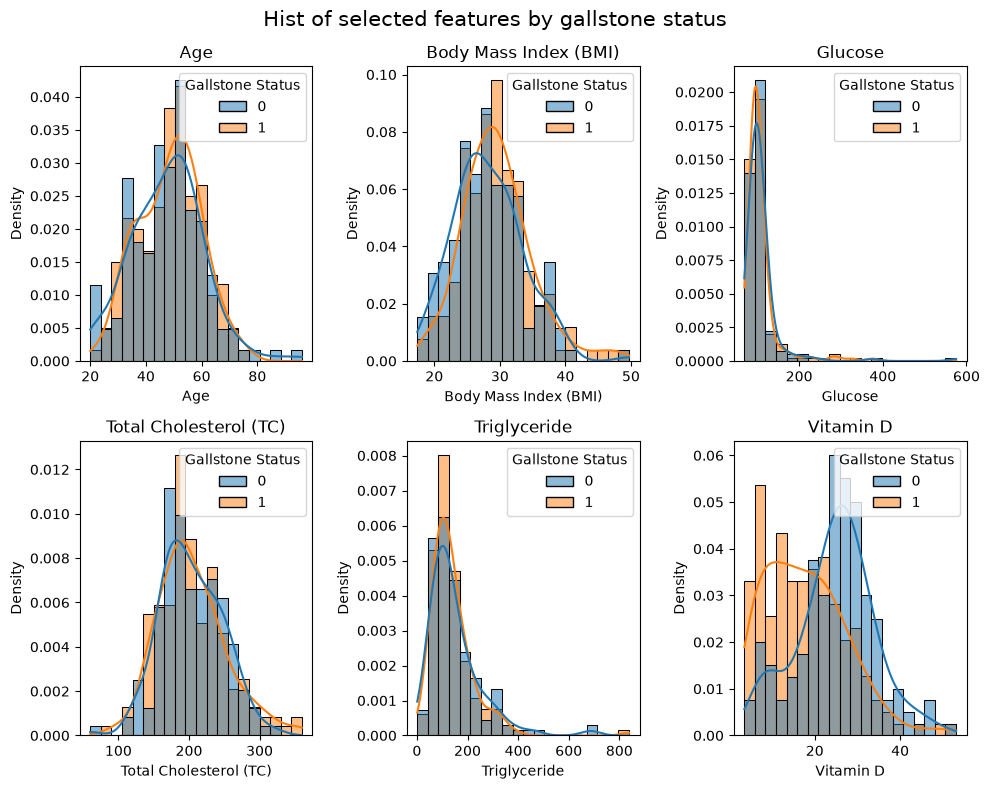

In [18]:
features = ["Age","Body Mass Index (BMI)","Glucose","Total Cholesterol (TC)","Triglyceride","Vitamin D"]
fig, axes = plt.subplots(2, 3, figsize=(10, 8))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data=galle_set, x=col, hue='Gallstone Status', bins=20, kde=True, stat='density', common_norm=False, ax=ax)
    ax.set_title(col)
plt.suptitle('Hist of selected features by gallstone status', fontsize=15)
plt.tight_layout(); plt.show()

**Distribution of Selected Features by Gallstone Status**

This plot of histograms compare the distributions of six features between with patient with (0) and without (1) gallstones. Parameters like Age,  BMI, glucose, total cholesterol, and triglyceride levels show considerable overlap between the two groups. This means limitied differences in their distributions. However, patients without gallstones tend to have higher vitamin D levels, representing one of the more noticeable difference between the groups. At the same time, glucose and triglyceride distributions are right-skewed, with a few extreme values.




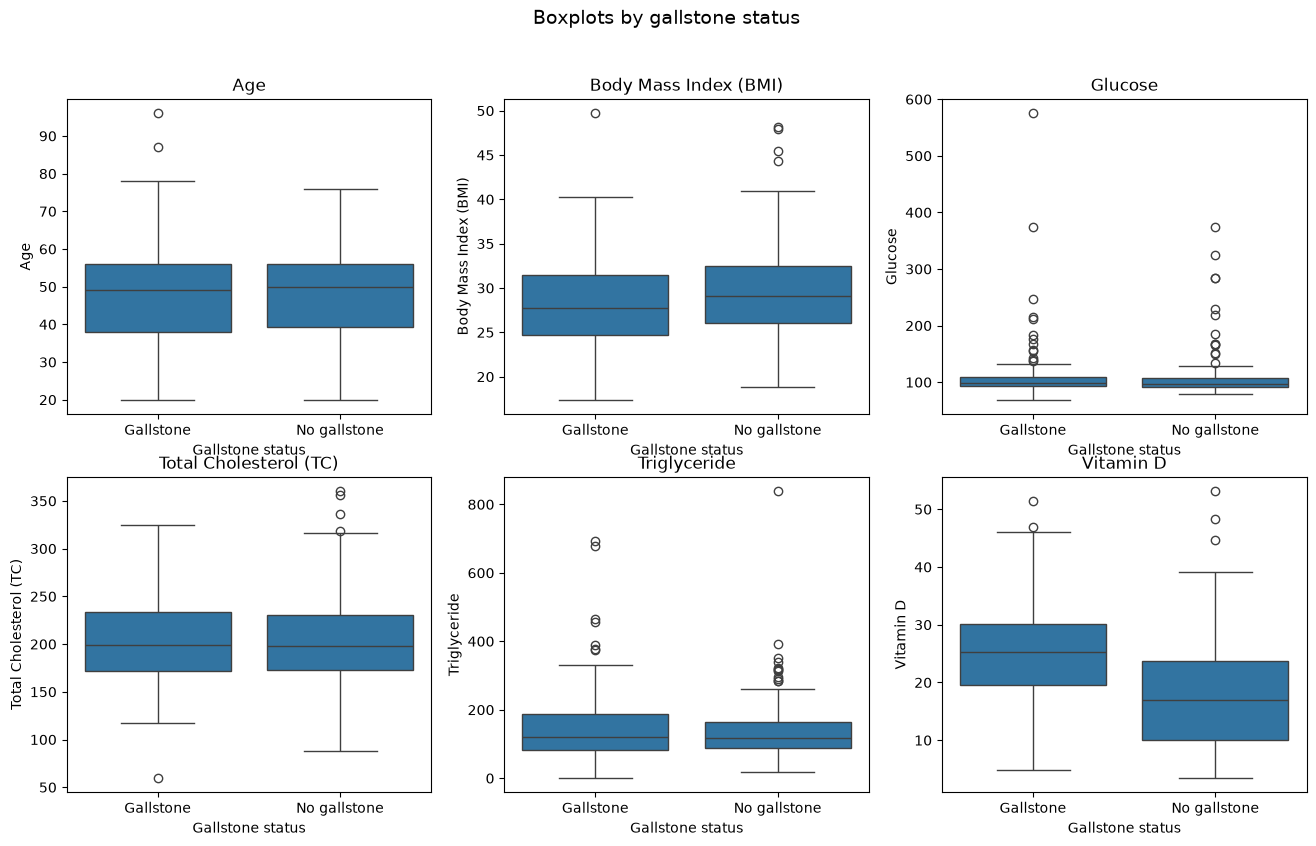

medians of groups:


,Age,Body Mass Index (BMI),Glucose,Total Cholesterol (TC),Triglyceride,Vitamin D
Status,,,,,,
Gallstone,49.0,27.70,99.0,199.0,119.0,25.27
No gallstone,50.0,29.15,97.0,198.0,118.5,17.00


In [19]:


fig, axes = plt.subplots(2, 3, figsize=(16, 9))
plot_data = galle_set.assign(Status=galle_set['Gallstone Status'].map({0:'Gallstone', 1:'No gallstone'}))
for ax, feature in zip(axes.flat, features):
    sns.boxplot(data=plot_data, x='Status', y=feature,
                order=['Gallstone', 'No gallstone'], ax=ax)
    ax.set(title=feature, xlabel='Gallstone status', ylabel=feature)
fig.suptitle('Boxplots by gallstone status', fontsize=14)
plt.show()
print('medians of groups:')
display(plot_data.groupby('Status')[features].median().reindex(['Gallstone','No gallstone']).round(2))


**Boxplots of Selected Features**
The boxplots show medians, interquartileranges and possible outliers separately for patients with and without gallstones. The table abow provides actual group medians. 





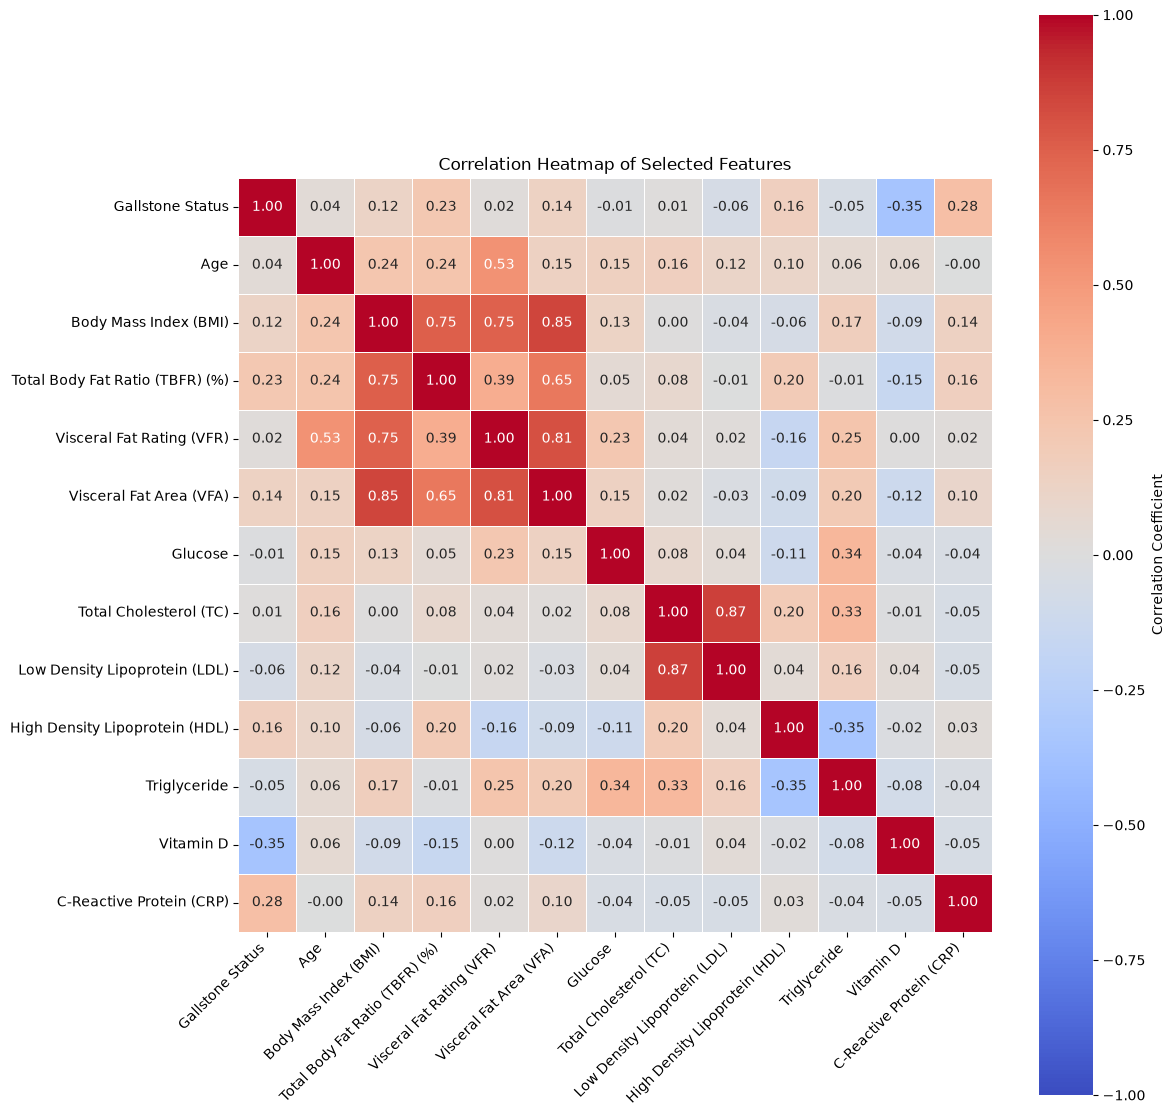

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select features
sel = [
    "Gallstone Status",
    "Age",
    "Body Mass Index (BMI)",
    "Total Body Fat Ratio (TBFR) (%)",
    "Visceral Fat Rating (VFR)",
    "Visceral Fat Area (VFA)",
    "Glucose",
    "Total Cholesterol (TC)",
    "Low Density Lipoprotein (LDL)",
    "High Density Lipoprotein (HDL)",
    "Triglyceride",
    "Vitamin D",
    "C-Reactive Protein (CRP)"
]

# Create correlation heatmap
plt.figure(figsize=(12, 12))

#sns.heatmap(galle_set[sel].corr(), annot=True, fmt=".2f", cmap="coolwarm", cbar=True, square=True, linewidths=0.5)

sns.heatmap(
    galle_set[sel].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"label": "Correlation Coefficient"}
)
plt.title("Correlation Heatmap of Selected Features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


The correlation heatmap shows the relationship between the 13 selected variables. These features were chosesn to compare realtionships between clinincal features and patient status.Deep red represents a strong positive correlation between varaibles and negative correlations are represented by blue.

 Features such as BMI, total body fat ratio, visceral fat rating and visceral fat area are correlated with each other. It gives an indication that these features consist of overlapping information about body composition. Total cholestrol and LDL also show a positive correlation, which is expected given their relationshop. The remianing features are weak or negative.

*Sign note:* `Gallstone Status` is coded 0 = gallstones and 1 = no gallstones, so a **positive** correlation with it means that the feature is **higher in patients without gallstones**. And negative correlation shows the reverse. 

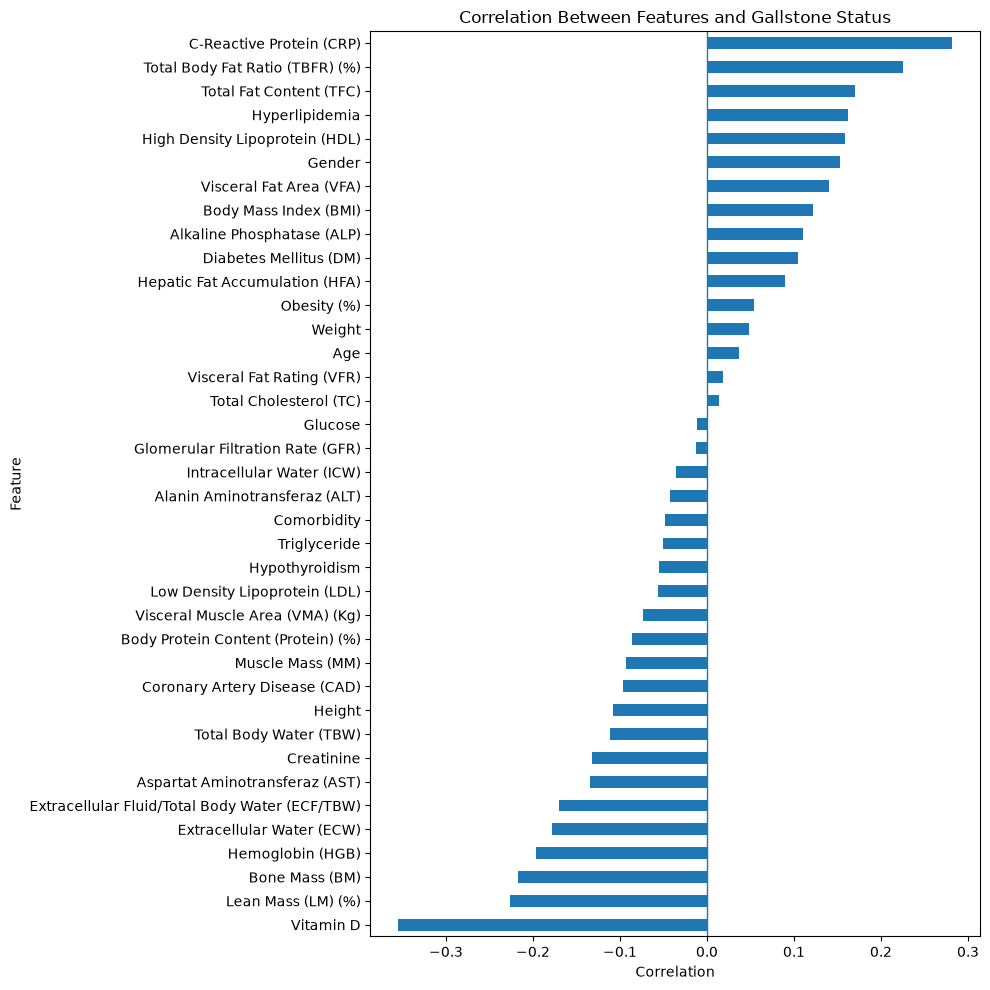

In [21]:
correlations = (
    galle_set.corr(numeric_only=True)["Gallstone Status"]
    .drop("Gallstone Status")
    .sort_values()
)

plt.figure(figsize=(10, 10))
correlations.plot(kind="barh")

plt.title("Correlation Between Features and Gallstone Status")
plt.xlabel("Correlation")
plt.ylabel("Feature")

plt.axvline(0, linewidth=1)
plt.tight_layout()
plt.show()

<span style="color:hotpink;"> The correlation plot was made ti visualize the linear relationship between the different features with gallstone status. C-Reative Proteing has the strongest correlation, before Total Body Fat Ratio, Total fat Contetnt, Hyperlipidemia and HDL. These values may be relevant predictors of gallstone status. On the lower part of the plot contains Vitamin D, Lean Mass and Bone Mass which are assocaited with lower occurende of gallstone. To compare to the boxplot result, age has a week correlation, which supports the observation that age is probably not connected to gallstone status.

## Preprocessing

<span style="color:hotpink;"> As the last step before machine learning, we will proceed with some preprocessing. Checking data types was done in the data overview part of the project and the result showed that the dataset contains numerical variables. Several categorical and binary variables are already numerically encoded. We will proceed with investigation of the value found in obesity and considaterion of scaling of the numerical features, as well as looking at outliers. 

In [22]:
#Looking for outliers using IQR method
#first find the numerical features in the dataset with more than 5 different values
continous_features=[
    column for column in galle_set.select_dtypes(include='number').columns
    if galle_set[column].nunique() > 5
]
print ("Selected continous_features:")
for feature in continous_features:
    print(feature)

Selected continous_features:
Age
Height
Weight
Body Mass Index (BMI)
Total Body Water (TBW)
Extracellular Water (ECW)
Intracellular Water (ICW)
Extracellular Fluid/Total Body Water (ECF/TBW)
Total Body Fat Ratio (TBFR) (%)
Lean Mass (LM) (%)
Body Protein Content (Protein) (%)
Visceral Fat Rating (VFR)
Bone Mass (BM)
Muscle Mass (MM)
Obesity (%)
Total Fat Content (TFC)
Visceral Fat Area (VFA)
Visceral Muscle Area (VMA) (Kg)
Glucose
Total Cholesterol (TC)
Low Density Lipoprotein (LDL)
High Density Lipoprotein (HDL)
Triglyceride
Aspartat Aminotransferaz (AST)
Alanin Aminotransferaz (ALT)
Alkaline Phosphatase (ALP)
Creatinine
Glomerular Filtration Rate (GFR)
C-Reactive Protein (CRP)
Hemoglobin (HGB)
Vitamin D


In [23]:
#check for outliers in continous features by using IQR method 
outlier_results=[]
for column in continous_features:
    Q1 = galle_set[column].quantile(0.25)
    Q3 = galle_set[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = galle_set[(galle_set[column] < lower_bound) | (galle_set[column] > upper_bound)]
    
    outlier_results.append({
        'Feature': column,
        'Lower bound': round(lower_bound, 2),
        'Upper bound': round(upper_bound, 2),
        'Number of outliers': len(outliers),
        'Outlier values': sorted(outliers[column].tolist())
    })

#Want to sort from most to fewest outliers
outlier_summary=pd.DataFrame(outlier_results)
outlier_summary=outlier_summary.sort_values(
    by='Number of outliers',
    ascending=False
)
display(outlier_summary)

,Feature,Lower bound,Upper bound,Number of outliers,Outlier values
28,C-Reactive Protein (CRP),-2.42,4.04,34,"[4.16, 4.2, 4.3, 4.5, 4.6, 4.7, 4.8, 4.8, 4.9,..."
24,Alanin Aminotransferaz (ALT),-9.38,53.62,27,"[54.0, 54.0, 54.0, 57.0, 57.0, 58.0, 58.0, 58...."
18,Glucose,66.50,134.50,25,"[138.0, 140.0, 142.0, 149.0, 152.0, 155.0, 157..."
23,Aspartat Aminotransferaz (AST),3.00,35.00,23,"[36.0, 37.0, 37.0, 38.0, 38.0, 38.0, 39.0, 40...."
22,Triglyceride,-50.50,305.50,20,"[307.0, 314.0, 315.0, 316.0, 320.0, 321.0, 321..."
25,Alkaline Phosphatase (ALP),16.00,128.00,12,"[7.0, 10.0, 14.0, 15.0, 130.0, 130.0, 131.0, 1..."
27,Glomerular Filtration Rate (GFR),70.51,134.89,12,"[43.74, 52.8, 54.99, 64.61, 65.51, 65.6, 66.5,..."
10,Body Protein Content (Protein) (%),10.02,21.88,8,"[5.56, 7.99, 9.05, 9.63, 21.92, 22.4, 22.72, 2..."
15,Total Fat Content (TFC),-0.33,45.88,7,"[46.3, 47.7, 50.0, 50.4, 55.2, 60.7, 62.5]"
7,Extracellular Fluid/Total Body Water (ECF/TBW),34.19,49.89,7,"[29.23, 30.05, 30.82, 34.09, 50.0, 50.0, 52.0]"


<span style="color:hotpink;"> For each continous variable, we calculate Q1 and Q3 and use these to find the IQR. Values below Q1 - 1.5 x IQR or above Q3 + 1.5 IQR are identified as potential outliers. It is important to understand potential outliers, as extreme values can be true values. The IQR method identifies unusal observations, but they may be correct. According to the result, some variable such as CRP, ALT, glucose, AST and triglyceride has more than 20 potential outliers. Most of these observations may represent valid clinical measurements, as they are not cleary outstanding with large differences between the numbers. Obesity had one value of 1954, which is one of the 7 potential outliers for this feature. Due to the results finding that BMI could be corresponding to obesity and the calue of 1954 is suspicously high, we put this value to NaN. If the obesity feature is necessary at all, can be considered in the feature selection. 

From the IQR results we want to dig deeper in four features. Obesity at 1954 is an extreme outlier. For HDL it is one value pointing out compared to the other. We will look into 273. 
Muscle mass at 4,7 is very low compared to the upper and lower bound. Body protein content at 5,56 is low compared to the rest. We need to investigate these observations. Within the values below. 

In [24]:
#Investigation of the suspicious outliers  
suspicious_rows=galle_set[
    (galle_set['Obesity (%)']>100) |
    (galle_set['High Density Lipoprotein (HDL)'] > 250) |
    (galle_set['Muscle Mass (MM)'] < 8) |
    (galle_set['Body Protein Content (Protein) (%)'] < 10)
]

#choose different features to compare if there is a pattern in the suspicious rows
display(suspicious_rows[[
    'Age',
    'Height',
    'Gender',
    'Weight',
    'Body Mass Index (BMI)',
    'Obesity (%)',
    'High Density Lipoprotein (HDL)',
    'Muscle Mass (MM)',
    'Body Protein Content (Protein) (%)',
    'Gallstone Status',
    'Lean Mass (LM) (%)',
    'Total Cholesterol (TC)',
    'Low Density Lipoprotein (LDL)',
    'Triglyceride'
]])

,Age,Height,Gender,Weight,Body Mass Index (BMI),Obesity (%),High Density Lipoprotein (HDL),Muscle Mass (MM),Body Protein Content (Protein) (%),Gallstone Status,Lean Mass (LM) (%),Total Cholesterol (TC),Low Density Lipoprotein (LDL),Triglyceride
23,57,170,0,143.5,49.7,125.60,46.0,78.8,7.99,0,57.70,172.0,111.0,112.0
181,41,173,1,56.3,18.8,14.40,46.0,40.7,5.56,1,76.20,180.0,117.0,106.0
205,46,155,1,78.4,32.6,48.20,47.0,4.7,13.50,1,63.14,240.0,120.0,150.0
209,64,150,1,102.1,45.4,106.30,45.0,51.6,12.27,1,53.28,153.0,85.0,157.0
239,51,150,1,65.9,29.3,1954.00,57.0,42.1,14.80,1,67.37,199.0,118.0,138.0
262,54,155,1,80.2,33.4,36.23,31.0,41.0,9.63,1,53.87,138.0,93.0,104.0
280,53,150,1,108.4,48.2,96.63,74.0,50.5,9.05,1,48.99,183.0,91.0,97.0
318,60,154,1,63.5,26.8,21.60,273.0,41.3,15.91,1,68.50,296.0,155.0,19.0


Particularly unusal values: obesity 1954, muscle mass 4.7, HDL 273 and BPC 5,56. This further ivestigation show that high BMI is also a connection between some of the suspicious observations. But it does not appear as high for all the unusal values. 
- Obesity: The high value for obesity at 1954 is obviously wrong. It can be a typo, missing a comma. This would instead give 19.54, which compared to the other values for obesity seems more valid. Since we do not know the right value for obesity, we replace the value with NaN and keep the other information about the patient. 
- Muscle mass: The value 4.7 is lower than the other given values. Compairing the value with height, wight and BMI, the muscle mass may be this low, but can not be sure the value is incorrecy.
- HDL: The value of 273 is much higher compared to other HDL values. 
- BPC: Also has a low value compared to other BPC values. The same patient has low BMI.  
Obesity is replaced with median. The other values are kept since we dont have enough evidence that they are incorrect. 

In [25]:

record_with_incorrect_obesity = galle_set["Obesity (%)"].eq(1954)  # Flag records with an incorrect obesity value.

imputer = SimpleImputer(strategy="median") # Create an imputer that uses the median to fill missing values.
imputer.fit(galle_set.loc[~record_with_incorrect_obesity, ["Obesity (%)"]])  # Fit the imputer using only valid obesity values.

galle_set.loc[record_with_incorrect_obesity, "Obesity (%)"] = imputer.statistics_[0]  # Replace incorrect obesity values with the median.

display(galle_set.loc[[239], ["Obesity (%)"]]) # Display the records that had incorrect obesity values shown new value corrected by median


,Obesity (%)
239,25.5


In [26]:
display(galle_set)

,Gallstone Status,Age,Gender,Comorbidity,Coronary Artery Disease (CAD),Hypothyroidism,Hyperlipidemia,Diabetes Mellitus (DM),Height,Weight,...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
0,0,50,0,0,0,0,0,0,185,92.8,...,40.0,134.0,20.0,22.0,87.0,0.82,112.47,0.0,16.0,33.0
1,0,47,0,1,0,0,0,0,176,94.5,...,43.0,103.0,14.0,13.0,46.0,0.87,107.10,0.0,14.4,25.0
2,0,61,0,0,0,0,0,0,171,91.1,...,43.0,69.0,18.0,14.0,66.0,1.25,65.51,0.0,16.2,30.2
3,0,41,0,0,0,0,0,0,168,67.7,...,59.0,53.0,20.0,12.0,34.0,1.02,94.10,0.0,15.4,35.4
4,0,42,0,0,0,0,0,0,178,89.6,...,30.0,326.0,27.0,54.0,71.0,0.82,112.47,0.0,16.8,40.6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
314,1,49,0,0,0,0,0,0,178,88.8,...,55.0,81.0,28.0,50.0,90.0,0.98,94.50,6.2,16.5,8.3
315,1,31,1,0,0,0,0,0,157,53.4,...,58.0,64.0,24.0,16.0,38.0,0.50,128.50,0.0,12.5,24.0
316,1,58,0,0,0,0,0,0,172,96.6,...,45.0,168.0,21.0,27.0,94.0,1.04,83.23,0.0,15.4,15.7
317,1,37,1,0,0,0,0,0,177,88.4,...,33.0,253.0,40.0,22.0,115.0,1.01,98.23,0.4,16.0,33.3


In [27]:
TARGET = "Gallstone Status"
CLASS_NAMES = ["Without gallstones", "With gallstones"]  # 0, 1

RANDOM_STATE = 14   # one seed for every random operation -> reproducible results
TEST_SIZE = 0.20    # 20 % held out, never touched until the final evaluation
MAX_ITERATIONS = 100000 # maximum number of iterations for the logistic regression solver
CV_SPLITS = 5       # folds per cross-validation round
CV_REPEATS = 10 

## Scaling

<span style="color:hotpink;"> Before applying machine learning, scaling is necessary due to the different ranges and units in the dataset. For this we use standardscaler. This method changes the features tp have a mean of 0 and a standard deviation of 1. The scaler is fitted to the training data and then applied to training and test data, to avoid data leakage. 

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#First we separate the features and the target variable 
X=galle_set.drop(columns=['Gallstone Status'])
y=galle_set['Gallstone Status']

#Further we split the dataset into training and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
print("Training data:", X_train.shape)
print("Test data:", X_test.shape)

Training data: (255, 38)
Test data: (64, 38)


In [29]:
#Scaling the features using StandardScaler
scaler=StandardScaler()

X_train[continous_features]=scaler.fit_transform(X_train[continous_features])
X_test[continous_features]=scaler.transform(X_test[continous_features])

X_train[continous_features].describe().round(2)

,Age,Height,Weight,Body Mass Index (BMI),Total Body Water (TBW),Extracellular Water (ECW),Intracellular Water (ICW),Extracellular Fluid/Total Body Water (ECF/TBW),Total Body Fat Ratio (TBFR) (%),Lean Mass (LM) (%),...,High Density Lipoprotein (HDL),Triglyceride,Aspartat Aminotransferaz (AST),Alanin Aminotransferaz (ALT),Alkaline Phosphatase (ALP),Creatinine,Glomerular Filtration Rate (GFR),C-Reactive Protein (CRP),Hemoglobin (HGB),Vitamin D
count,255.00,255.00,255.00,255.00,255.00,255.00,255.00,255.00,255.00,255.00,...,255.00,255.00,255.00,255.00,255.00,255.00,255.00,255.00,255.00,255.00
mean,0.00,0.00,0.00,-0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,...,-0.00,-0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.30,-2.28,-2.31,-2.07,-3.45,-2.58,-1.81,-4.07,-2.56,-2.73,...,-1.30,-1.38,-0.79,-0.82,-2.79,-1.95,-3.97,-0.37,-3.45,-1.78
25%,-0.83,-0.75,-0.68,-0.65,-0.79,-0.69,-0.77,-0.57,-0.75,-0.78,...,-0.50,-0.63,-0.41,-0.42,-0.61,-0.82,-0.53,-0.37,-0.61,-0.81
50%,0.15,0.07,-0.10,-0.09,-0.10,-0.01,-0.12,-0.09,-0.08,0.08,...,-0.18,-0.26,-0.24,-0.28,-0.14,-0.02,0.17,-0.32,0.03,0.03
75%,0.63,0.78,0.64,0.53,0.78,0.72,0.70,0.54,0.80,0.75,...,0.33,0.28,0.09,0.08,0.53,0.69,0.61,-0.05,0.70,0.69
max,3.89,2.21,3.91,3.85,3.19,3.39,6.11,3.03,2.73,2.57,...,11.94,6.68,9.47,11.51,5.20,3.73,2.09,7.75,2.23,2.97


<span style="color:hotpink;"> The result show that the scaled training features have a mean equal to 0. The standard deviation is 1. This mean that the scaling was successful. 

## Feature selection

<span style="color:hotpink;"> In the feature selection we want to identify which features that are important to predicate gallstone status. We have earlier made different vizulatisations and the results from these. The strongest negative correlation was Vitamin D and lean mass(LM). The strongest positive correlation was C-reactive Protein(CRP) and total body fat ratio (TBFR). These results are taken from the diagrams already made. To choose which features to work with further, we find the features with the highest correlation.

In [30]:
#Feature selection based on correlation
correlation=galle_set.corr(numeric_only=True)['Gallstone Status'] 

#Sort by absolute correlation. Want to find the most correlatedfeatures, even whether the correlation is positive or negative. 
correlation=correlation.drop('Gallstone Status')
top_features=correlation.abs().sort_values(ascending=False).head(10)

print(top_features)

Vitamin D                                         0.354873
C-Reactive Protein (CRP)                          0.281995
Lean Mass (LM) (%)                                0.225749
Total Body Fat Ratio (TBFR) (%)                   0.225470
Bone Mass (BM)                                    0.216570
Hemoglobin (HGB)                                  0.196872
Extracellular Water (ECW)                         0.178436
Total Fat Content (TFC)                           0.170158
Extracellular Fluid/Total Body Water (ECF/TBW)    0.169826
Hyperlipidemia                                    0.161901
Name: Gallstone Status, dtype: float64


<span style="color:hotpink;"> The highest correlation is at 0.35, which is considered low. Vitamin D and CRP has the strongest correlation with gallstone status. Next step is to check correlation between these top 10 features. If two features they have a high correlation, they may contain similar information. This result will help us to make the decision which feature to use in the model.  

In [31]:
#Check correlation between top 10 features
selected_features=top_features.index
feature_correlation=galle_set[selected_features].corr()

display(feature_correlation.round(2))

,Vitamin D,C-Reactive Protein (CRP),Lean Mass (LM) (%),Total Body Fat Ratio (TBFR) (%),Bone Mass (BM),Hemoglobin (HGB),Extracellular Water (ECW),Total Fat Content (TFC),Extracellular Fluid/Total Body Water (ECF/TBW),Hyperlipidemia
Vitamin D,1.00,-0.05,0.16,-0.15,0.06,0.03,0.08,-0.16,0.13,0.03
C-Reactive Protein (CRP),-0.05,1.00,-0.16,0.16,-0.07,-0.18,-0.08,0.14,-0.05,-0.02
Lean Mass (LM) (%),0.16,-0.16,1.00,-0.99,0.24,0.40,0.10,-0.86,-0.40,-0.14
Total Body Fat Ratio (TBFR) (%),-0.15,0.16,-0.99,1.00,-0.22,-0.40,-0.10,0.87,0.40,0.14
Bone Mass (BM),0.06,-0.07,0.24,-0.22,1.00,0.52,0.82,0.14,-0.19,-0.09
Hemoglobin (HGB),0.03,-0.18,0.40,-0.40,0.52,1.00,0.54,-0.17,-0.18,-0.18
Extracellular Water (ECW),0.08,-0.08,0.10,-0.10,0.82,0.54,1.00,0.28,0.12,-0.05
Total Fat Content (TFC),-0.16,0.14,-0.86,0.87,0.14,-0.17,0.28,1.00,0.26,0.10
Extracellular Fluid/Total Body Water (ECF/TBW),0.13,-0.05,-0.40,0.40,-0.19,-0.18,0.12,0.26,1.00,0.16
Hyperlipidemia,0.03,-0.02,-0.14,0.14,-0.09,-0.18,-0.05,0.10,0.16,1.00


<span style="color:hotpink;"> Lean mass and total body fat ratio both has -0,99. These to features most likely contain much of the same information. The same is body fat ratio and total fat content with 0,87, and bone mass and extracellular water with 0,82. On the other side, Vitamin D and CRP has a collereation at -0,05. Based on this analysis we want to keep features:
- Lean mass or total body fat ratio (-0,99): keep one of them
- Total fat content: strong correlation to lean mass(-0,86) and total body fat ratio(0,87)
- Bone mass or extracellular water (0,82): keep on of them

In [32]:
#Early feature selection basen on the correlation analysis, which the feature we want to continue with
SELECTED_FEATURES=[
    'Vitamin D',
    'C-Reactive Protein (CRP)',
    'Total Body Fat Ratio (TBFR) (%)',
    'Bone Mass (BM)',
    'Hemoglobin (HGB)',
    'Extracellular Fluid/Total Body Water (ECF/TBW)',
    'Hyperlipidemia'
]

print("Number of selected features:", len(SELECTED_FEATURES))
print(SELECTED_FEATURES)

Number of selected features: 7
['Vitamin D', 'C-Reactive Protein (CRP)', 'Total Body Fat Ratio (TBFR) (%)', 'Bone Mass (BM)', 'Hemoglobin (HGB)', 'Extracellular Fluid/Total Body Water (ECF/TBW)', 'Hyperlipidemia']


### Preprocessing summary

<span style="color:hotpink;">
The main steps of the preprocessing, based on the data exploration was as following:

1. Outlier handling looking for very low or very high values. One value was defined as unrealistic. Obesity at 1954 was replaced with NaN. We retained the other suspicious values, since we couldnt confirm wether they were incorrect. 
2. The dataset was split into 80% training data and 20 % test data by stratified sampling. 
4. Continous features was standardized by using StandardScaler, fitted on the training data. Further this was used on the test data to avoid data leakage. Binary features were not scaled. 
5. Correlation analysis was used to investigate the correlation between the features, to help us choose a selection of features for further modelling. 

## Logistic Regression

AZ: Describe the model WIP!

The model is trained and evaluated in the following steps:

1. **Features and target:** `Gallstone Status` is the target for the moddel. All other columns in `dataset_df` can be used as predictors/features
2. **Train/test split:** The data is split into training and test sets. we have to stratify the target to balance both sets.
3. **Scaling:** Features are standardized to minimum ans maximun values of 0 to 1, so the logistic regression return more reliable values.
4. **Model fitting:** A `LogisticRegression` model is fitted on the training data.
5. **Evaluation:** Test-set predictions are scored with accuracy, a confusion matrix, and a classification report (precision, recall, F1).

Splitting dataset-uci into testing and validation set. Validation (unseen) set will only be used for final validation of models

In [33]:
validation_set_df = galle_set.sample(n=30, random_state=RANDOM_STATE) # unseen validation set

validation_set_df.to_csv("dataset_uci_validation_set.csv", index=False) 
print("Saved sampled records to dataset_uci_validation_set.csv")

testing_set_df = galle_set.drop(validation_set_df.index)
testing_set_df.to_csv("dataset_uci_testing_set.csv", index=False)
print("Saved the rest of the records to dataset_uci_testing_set.csv")

Saved sampled records to dataset_uci_validation_set.csv
Saved the rest of the records to dataset_uci_testing_set.csv


In [34]:
print(f"Missing values : {testing_set_df.isna().sum().sum()}")
print(f"Duplicate rows : {testing_set_df.duplicated().sum()}")
print("\nClass balance:")
print(testing_set_df[TARGET].value_counts().rename(index=dict(enumerate(CLASS_NAMES))))

Missing values : 0
Duplicate rows : 0

Class balance:
Gallstone Status
Without gallstones    146
With gallstones       143
Name: count, dtype: int64


AZ: In this step all spliting and scaling needed to be repeated since Logistic Regression can not handel "NaN" values. Imputment using median stategy has been used instead.  

In [35]:
X = testing_set_df.drop(columns=[TARGET])
y = testing_set_df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

scaled_logreg_model = make_pipeline( # StandardScaler and LogisticRegression pipeline
    StandardScaler(),
    LogisticRegression(
        max_iter=MAX_ITERATIONS, # Maximum number of iterations for the solver
        random_state=RANDOM_STATE # Random state for reproducibility
    )
)

scaled_logreg_model.fit(X_train, y_train) # Fit the scaled logistic regression model to the training data

scaled_logreg_score = scaled_logreg_model.score(X_test, y_test) # Evaluate the model on the test data
y_pred_scaled_logreg_model = scaled_logreg_model.predict(X_test) # Predict the target variable for the test data

print("Scaled Logistic Regression Score:", scaled_logreg_score)

Scaled Logistic Regression Score: 0.8275862068965517


Confusion matrix for the logistic regression model


In [36]:
cv_scores = cross_val_score(scaled_logreg_model, X, y, cv=RepeatedStratifiedKFold(
    n_splits=CV_SPLITS,
    n_repeats=CV_REPEATS,
    random_state=RANDOM_STATE,
))
print("Cross-Validation Scores:", cv_scores)
print("Mean Cross-Validation Score:", cv_scores.mean())
print("Standard Deviation of Cross-Validation Scores:", cv_scores.std())
print("Number of Cross-Validation Scores:", len(cv_scores))
print("All Cross-Validation Scores:", cv_scores)
    

Cross-Validation Scores: [0.74137931 0.81034483 0.75862069 0.84482759 0.71929825 0.87931034
 0.72413793 0.86206897 0.74137931 0.75438596 0.77586207 0.81034483
 0.82758621 0.79310345 0.84210526 0.67241379 0.86206897 0.79310345
 0.86206897 0.80701754 0.72413793 0.89655172 0.77586207 0.72413793
 0.77192982 0.82758621 0.84482759 0.86206897 0.74137931 0.66666667
 0.84482759 0.60344828 0.81034483 0.84482759 0.73684211 0.84482759
 0.82758621 0.75862069 0.74137931 0.66666667 0.82758621 0.70689655
 0.70689655 0.84482759 0.77192982 0.70689655 0.68965517 0.87931034
 0.79310345 0.71929825]
Mean Cross-Validation Score: 0.7808469449485784
Standard Deviation of Cross-Validation Scores: 0.06652461416727229
Number of Cross-Validation Scores: 50
All Cross-Validation Scores: [0.74137931 0.81034483 0.75862069 0.84482759 0.71929825 0.87931034
 0.72413793 0.86206897 0.74137931 0.75438596 0.77586207 0.81034483
 0.82758621 0.79310345 0.84210526 0.67241379 0.86206897 0.79310345
 0.86206897 0.80701754 0.7241379

In [37]:
cnf_matrix = metrics.confusion_matrix(y_test, y_pred_scaled_logreg_model)
print("Confusion Matrix:")
print(cnf_matrix)

Confusion Matrix:
[[24  5]
 [ 5 24]]


In [38]:
target_names = ['without Gallstone', 'with Gallstone']
print(classification_report(y_test, y_pred_scaled_logreg_model, target_names=target_names))

                   precision    recall  f1-score   support

without Gallstone       0.83      0.83      0.83        29
   with Gallstone       0.83      0.83      0.83        29

         accuracy                           0.83        58
        macro avg       0.83      0.83      0.83        58
     weighted avg       0.83      0.83      0.83        58



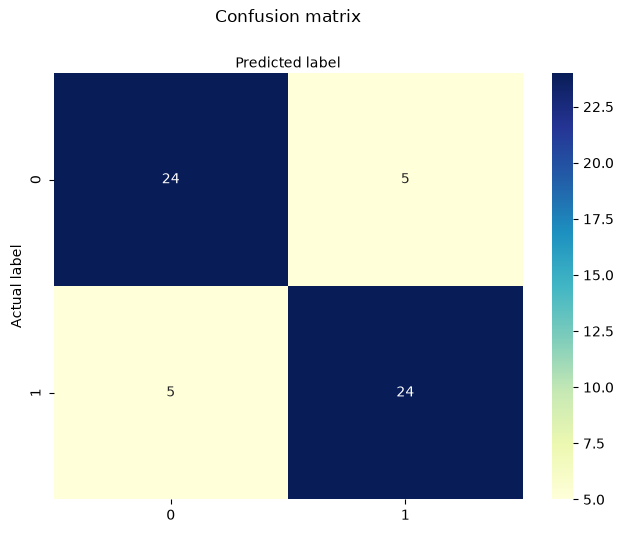

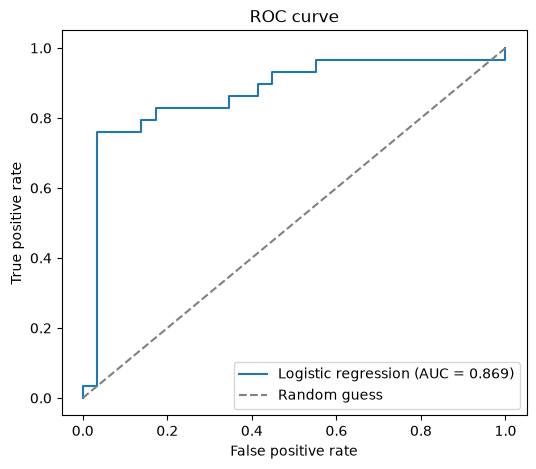

In [39]:
class_names=[0,1] # name  of classes
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)
# create heatmap
sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, cmap="YlGnBu" ,fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')


y_pred_proba = scaled_logreg_model.predict_proba(X_test)[:, 1]   
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)   # false alarm rate and hit rate at every cut-off
auc = roc_auc_score(y_test, y_pred_proba)   # one number for the whole curve

plt.figure(figsize=(6, 5))   # make the picture a fixed size
plt.plot(fpr, tpr, label=f"Logistic regression (AUC = {auc:.3f})")   # real label, rounded AUC
plt.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random guess")   # the line a coin flip would make
plt.xlabel("False positive rate")   # axis name
plt.ylabel("True positive rate")   # name of the axis
plt.title("ROC curve")   
plt.legend(loc="lower right")   # show the labels in the bottom right
plt.show()   # show the picture

In [40]:
X_val = validation_set_df[X_train.columns]
y_val = validation_set_df[TARGET]

validation_score = scaled_logreg_model.score(X_val, y_val)
print(f"Final Validation accuracy: {validation_score:.3f}")

print("\nConfusion matrix:")
y_pred_val = scaled_logreg_model.predict(X_val)
print(confusion_matrix(y_val, y_pred_val))

print("\nClassification report:")
print(classification_report(y_val, y_pred_val, zero_division=0))

Final Validation accuracy: 0.833

Confusion matrix:
[[14  1]
 [ 4 11]]

Classification report:
              precision    recall  f1-score   support

           0       0.78      0.93      0.85        15
           1       0.92      0.73      0.81        15

    accuracy                           0.83        30
   macro avg       0.85      0.83      0.83        30
weighted avg       0.85      0.83      0.83        30



# Decision Tree

Creating initial tree with max debth 3

In [ ]:
# Defining features and target variable for decision tree models
dt_class_names = ["With gallstones (0)", "Without gallstones (1)"]
dt_cv = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)

# Defining models
dt_models = {
    "Initial tree": tree.DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Depth 3 tree": tree.DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}

# Evaluating models using cross-validation
dt_cv_scores = {
    name: cross_val_score(model, X_train, y_train, cv=dt_cv, scoring="accuracy").mean()
    for name, model in dt_models.items()
}

Tuning parameter combinations using training data

In [ ]:
# Setting up hyperparameter grid
dt_param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [2, 3, 4, 5, 6, None],
    "min_samples_split": [2, 10, 20],
    "min_samples_leaf": [1, 3, 5, 10],
    "ccp_alpha": [0.0, 0.005, 0.02],
}

# Performing grid search
dt_search = GridSearchCV(
    dt_models["Initial tree"], 
    dt_param_grid, 
    cv=dt_cv, 
    scoring="accuracy"
)

# Fitting grid search to training data
dt_search.fit(X_train, y_train)
dt_models["Tuned tree"] = dt_search.best_estimator_
dt_cv_scores["Tuned tree"] = np.float64(dt_search.best_score_)

print("Best parameters:", dt_search.best_params_)

Best parameters: {'ccp_alpha': 0.0, 'criterion': 'gini', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}


Comparing training data and test results

In [ ]:
# Setting up dictionaries to store predictions, probabilities and results
dt_predictions = {}
dt_probabilities = {} 
dt_rows = []

# Evaluating decision tree models
for name, model in dt_models.items():
    model.fit(X_train, y_train)
    dt_predictions[name] = model.predict(X_test)
    probabilities = np.asarray(model.predict_proba(X_test))
    dt_probabilities[name] = probabilities[:, 0]       
    dt_rows.append({
        "Model": name, "CV accuracy": dt_cv_scores[name],
        "Train accuracy": model.score(X_train, y_train),
        "Test accuracy": model.score(X_test, y_test),
        "Gallstone recall": metrics.recall_score(y_test, dt_predictions[name], pos_label=0),
        "ROC-AUC": metrics.roc_auc_score(y_test == 0, dt_probabilities[name]),
    })

# Create a DataFrame to display the results
dt_results = pd.DataFrame(dt_rows).set_index("Model")

# Displaying the results
display(dt_results.round(3))
print(metrics.classification_report(
    y_test, dt_predictions["Tuned tree"], 
    labels=[0, 1],
    target_names=dt_class_names, 
    digits=3, 
    zero_division=0
))

,CV accuracy,Train accuracy,Test accuracy,Gallstone recall,ROC-AUC
Model,,,,,
Initial tree,0.719,1.000,0.655,0.621,0.655
Depth 3 tree,0.705,0.810,0.707,0.862,0.796
Tuned tree,0.758,0.931,0.655,0.690,0.669


                        precision    recall  f1-score   support

   With gallstones (0)      0.645     0.690     0.667        29
Without gallstones (1)      0.667     0.621     0.643        29

              accuracy                          0.655        58
             macro avg      0.656     0.655     0.655        58
          weighted avg      0.656     0.655     0.655        58



Plotting training and test accuracy

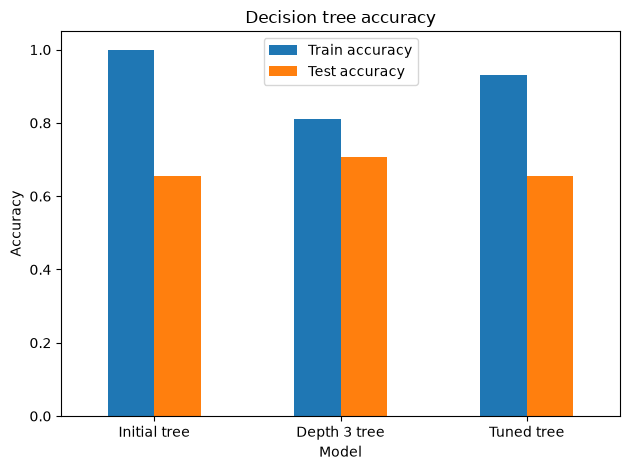

In [ ]:
dt_results[["Train accuracy", "Test accuracy"]].plot.bar(rot=0, ylim=(0, 1.05))

plt.title("Decision tree accuracy")
plt.ylabel("Accuracy")
plt.tight_layout()
plt.show()

Plotting confusion matrices for the initial and tuned trees

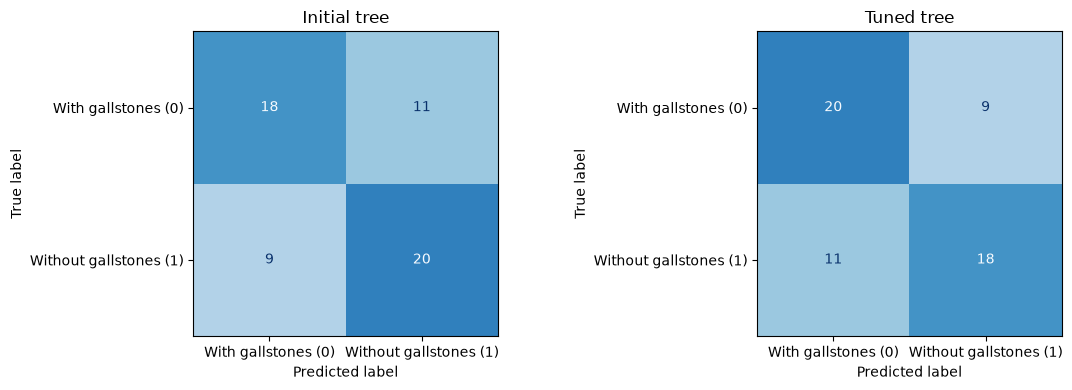

In [ ]:
fig, axes = plt.subplots(
    1, 
    2, 
    figsize=(12, 4)
)

for ax, name in zip(axes, ["Initial tree", "Tuned tree"]):
    metrics.ConfusionMatrixDisplay.from_predictions(
        y_test, 
        dt_predictions[name], 
        labels=[0, 1], 
        display_labels=dt_class_names,
        ax=ax, 
        cmap="Blues", 
        colorbar=False,
        im_kw={"vmin": 0, "vmax": y_test.value_counts().max()}
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

Plotting ROC curves with gallstones as the positive class

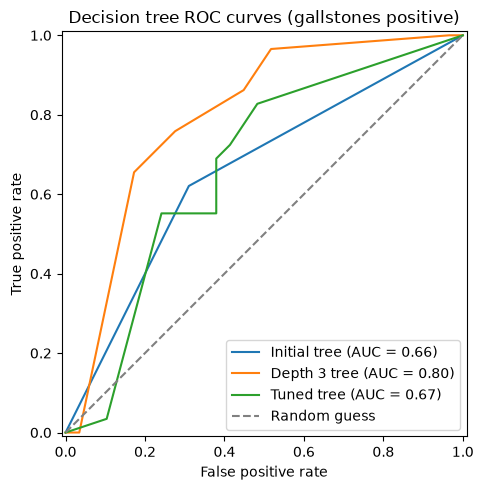

In [47]:
fig, ax = plt.subplots(figsize=(6, 5))

for name in dt_models:
    metrics.RocCurveDisplay.from_predictions(
        y_test == 0, 
        dt_probabilities[name], 
        name=name, 
        ax=ax
    )

ax.plot(
    [0, 1], 
    [0, 1], 
    "--", 
    color="grey", 
    label="Random guess"
)

ax.set(
    title="Decision tree ROC curves (gallstones positive)",
    xlabel="False positive rate", 
    ylabel="True positive rate"
)

ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

Visualizing the first three levels of the tuned tree

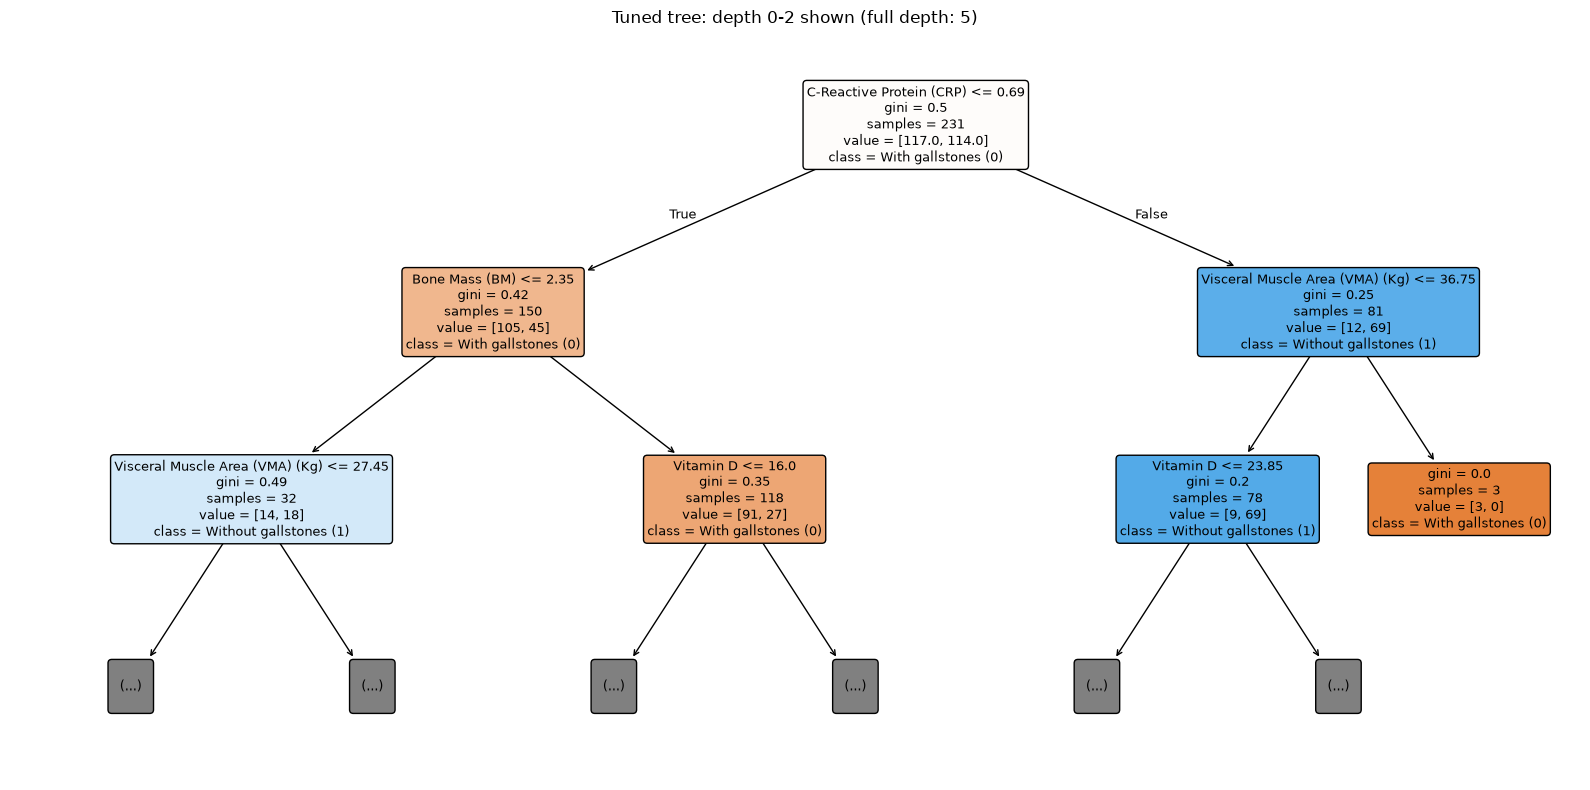

In [52]:
dt_best = dt_models["Tuned tree"]

plt.figure(figsize=(16, 8))
tree.plot_tree(
    dt_best, 
    feature_names=list(X_train.columns), 
    class_names=dt_class_names,
    filled=True, 
    rounded=True, 
    max_depth=2, 
    precision=2, 
    fontsize=9
)

plt.title(f"Tuned tree: depth 0-2 shown (full depth: {dt_best.get_depth()})")
plt.tight_layout()
plt.show()

Checking how tree depth affects training and cross-validation accuracy

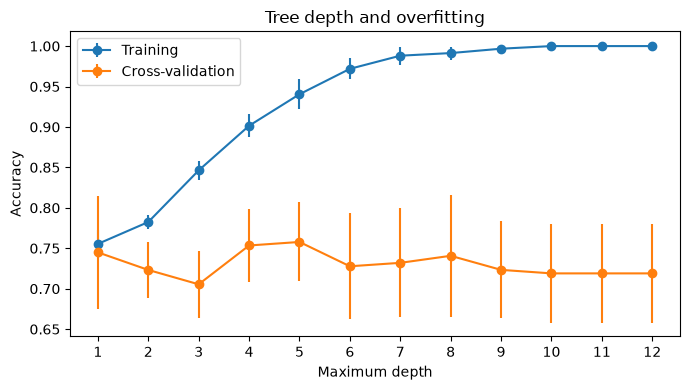

In [ ]:
# Setting up range of maximum depths to evaluate
dt_depths = np.arange(1, 13)

# Evaluating model for different maximum depths
dt_train_scores, dt_validation_scores = validation_curve(
    dt_models["Initial tree"], 
    X_train, 
    y_train, 
    param_name="max_depth",
    param_range=dt_depths, 
    cv=dt_cv, 
    scoring="accuracy"
)


# Plotting the validation curve
plt.figure(figsize=(7, 4))

for scores, name in [(dt_train_scores, "Training"), (dt_validation_scores, "Cross-validation")]:
    plt.errorbar(
        dt_depths, 
        scores.mean(axis=1), 
        yerr=scores.std(axis=1), 
        fmt="o-", 
        label=name
    )

plt.xlabel("Maximum depth")
plt.ylabel("Accuracy")
plt.title("Tree depth and overfitting")
plt.xticks(dt_depths)
plt.legend()
plt.tight_layout()
plt.show()

## References

1. Data camp Understanding Logistic Regression in Python - https://www.datacamp.com/datalab/w/11b0dd9d-49be-429d-992e-45f73b3c23fb#understanding-logistic-regression-in-python 
2. Scikit-learn: LogisticRegression - https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html
3. Scikit-learn: Decision Trees - https://scikit-learn.org/stable/modules/tree.html
4. Statistics Calculator - Regression:  https://numiqo.com/statistics-calculator/regression